# <b> <font color='#A20025'> Appendix I &middot; Notebook 1 of 5: Diffusion Models, from the Ground Up</font> </b>

*This is a bonus notebook accompanying Appendix I of [Build AI Drug Discovery Pipelines](https://github.com/nrflynn2/ml-drug-discovery). It is self-contained and runnable end to end; read it side by side with the appendix. This notebook builds intuition for forward noising and learned reverse denoising on a 2-D toy.*

Welcome to the first stop on our generative-modeling tour. Before you generate *molecules*, you need a gut feeling for how a **diffusion model** actually turns noise into structure. That is much easier to *see* in two dimensions than in the high-dimensional space of chemical graphs; so in this notebook you will build a compact **DDPM** (Denoising Diffusion Probabilistic Model) on a 2-D toy and watch every moving part.

Here is the whole idea in one breath: **destroy your data with noise in tiny steps, then train a neural network to undo one step at a time.** Sampling is just running that learned "undo" button from pure noise back to data.

By the end you will have:
- Watched the **forward process** dissolve a clean dataset into Gaussian static.
- Trained a small **noise-predicting** network on CPU in about a minute.
- Generated new samples by running the **reverse process**, and animated a single denoising trajectory.
- Built a **second sampler**, DDIM, on the same trained weights, and seen that the sampler is a choice independent of the model.
- Seen the catch that motivates the rest of the chapter: **cut the number of reverse steps and quality falls apart.**

> This notebook is self-contained and Colab-friendly. Notebook 2 will attack the *same* target distribution with **flow matching**; so you can compare the two approaches head-to-head.

## <b> <font color='#A20025'> Environment Setup</font> </b>

Run the cell below once. On **Google Colab** it installs the two packages that are not pre-loaded (`POT` for distribution distances later, plus a couple of niceties); PyTorch, NumPy, SciPy, scikit-learn, and Matplotlib already ship with Colab. Locally, it is a no-op if you already have them.

In [5]:
# --- Colab-friendly setup: safe to re-run ---
import importlib, subprocess, sys
def _ensure(pkg, import_name=None):
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
for pkg, name in [("scikit-learn", "sklearn"), ("POT", "ot"), ("matplotlib", "matplotlib")]:
    _ensure(pkg, name)

# Keep CPU thread use modest & reproducible (this whole notebook runs on CPU)
import os
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
print("Setup complete. CPU-only; no GPU required.")

Setup complete. CPU-only; no GPU required.


### <b> <font color='#A20025'> Import Packages</font> </b>

In [7]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

torch.set_num_threads(4)
torch.manual_seed(0); np.random.seed(0)
DEVICE = "cpu"   # everything here is small enough to stay on CPU
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

torch 2.13.0+cu130 | CUDA available: False


## <b> <font color='#A20025'> One target, two notebooks</font> </b>

Every generative model needs something to generate. Throughout this notebook **and** Notebook 2 you will use the *same* 2-D target so the two methods are directly comparable:

- **Source distribution** (where samples start): a standard 2-D Gaussian, $\mathcal{N}(0, I)$; easy to sample, structureless.
- **Target distribution** (what you want to learn): scikit-learn's **two interleaving half-moons**, lightly standardized to zero mean and unit variance.

The two-moons shape is a favorite teaching target for a reason: it is **not** something a single Gaussian can capture. The two crescents curl around each other, so a model has to learn *curved, multi-modal* structure; a miniature stand-in for the awkward geometry of real data manifolds (like the space of drug-like molecules you will meet later in the chapter).

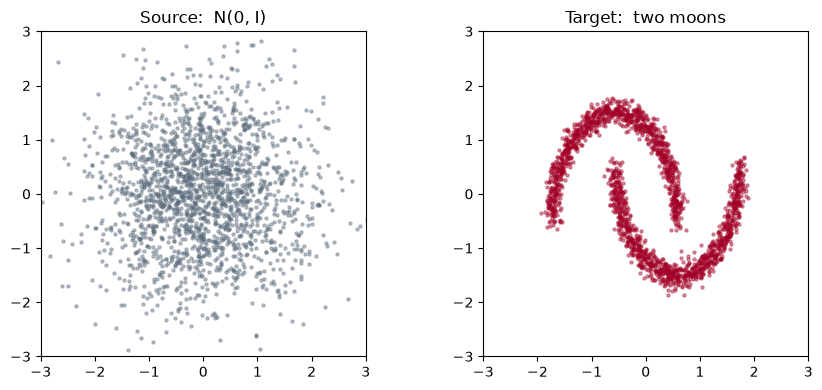

In [10]:
# ---- SHARED TARGET (identical in Notebook 1 and Notebook 2) ----
# Fixed standardization constants so the target's scale is stable across every draw.
_Xref, _ = make_moons(n_samples=100_000, noise=0.06, random_state=0)
MOON_MEAN = _Xref.mean(0).astype(np.float32)
MOON_STD  = _Xref.std(0).astype(np.float32)

def sample_target(n, seed=None):
    """Draw n points from the target: two standardized half-moons."""
    X, _ = make_moons(n_samples=n, noise=0.06, random_state=seed)
    return ((X.astype(np.float32) - MOON_MEAN) / MOON_STD)

def sample_source(n, generator=None):
    """Draw n points from the source: standard normal N(0, I)."""
    return torch.randn(n, 2, generator=generator)

# Look at both distributions side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
src = sample_source(2000).numpy(); tgt = sample_target(2000, seed=1)
for ax, data, title, c in [(axes[0], src, "Source:  N(0, I)", "#5B6B7B"),
                           (axes[1], tgt, "Target:  two moons", "#A20025")]:
    ax.scatter(data[:, 0], data[:, 1], s=5, alpha=0.4, color=c)
    ax.set_title(title); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
fig.tight_layout(); plt.show()

## <b> <font color='#A20025'> Forward noising: turning data into static</font> </b>

The **forward process** is the easy half; there is nothing to learn. You take a clean data point $x_0$ and progressively stir in Gaussian noise over $T$ steps until, at step $T$, essentially nothing but static remains.

The convenient part of DDPM is that you never have to add noise one step at a time. Thanks to a bit of Gaussian algebra you can jump *straight* to the noised version at **any** step $t$ in one shot:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 \;+\; \sqrt{1-\bar\alpha_t}\,\varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I)$$

Read it intuitively: $\bar\alpha_t$ starts near **1** (mostly signal, a little noise) and decays toward **0** (almost pure noise). The schedule of how fast $\bar\alpha_t$ falls is your choice; you will use the smooth **cosine schedule**, which noises gently at first and is a common modern default.

Watch a batch of moons dissolve as $t$ climbs:

> **Caution: build the ladder from betas, not from the curve.** It is tempting to read
$\bar\alpha_t$ straight off the cosine curve and use it as the schedule. Do that and
$\bar\alpha_0$ comes out to exactly **1.0**, which says step 0 adds *no* noise at all. That
looks harmless until you sample: the reverse update below divides by $\beta_t$, which is
zero at that step, so the final denoising step evaluates $0/0$ and every sample comes back
as `NaN`. The fix is to define the schedule the way the reverse process consumes it, as a
list of **per-step** $\beta_t$ values clamped to a safe range, and to get $\bar\alpha_t$ by
multiplying them up. You will get $\bar\alpha_0 = 0.99975$ instead of 1.0; a difference of
one part in four thousand that is the difference between working samplers and a notebook
full of `NaN`.

alpha_bar[0]   = 0.99975      (step 0 keeps nearly all the signal)
alpha_bar[199] = 6.072e-08   (step 199 is essentially pure noise)


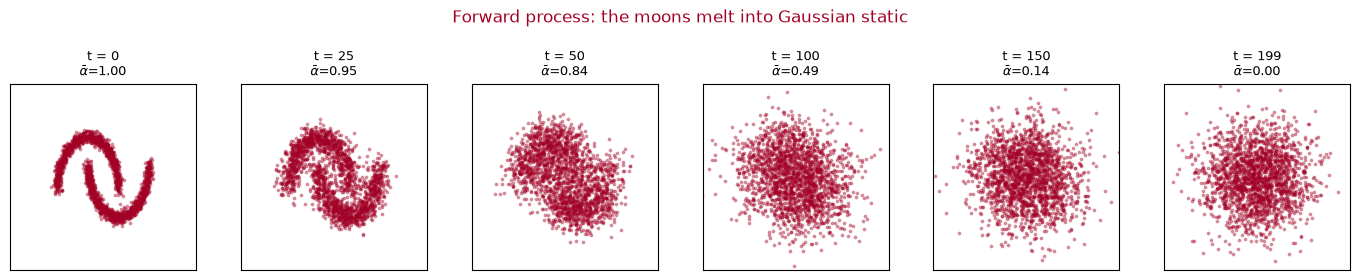

In [13]:
def cosine_betas(T, s=0.008):
    """Cosine noise schedule (Nichol & Dhariwal, 2021), returned as PER-STEP betas.

    We build the ladder from betas rather than reading alpha_bar off the cosine curve
    directly, because the reverse process consumes per-step betas. Clamping each beta to
    [1e-8, 0.999] keeps every reverse step well posed (see the Caution above).
    """
    steps = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos(((steps / T) + s) / (1 + s) * math.pi / 2) ** 2
    abar_curve = f / f[0]                              # raw cosine curve; abar_curve[0] == 1.0
    betas = 1 - (abar_curve[1:] / abar_curve[:-1])      # per-step noise fraction
    return betas.clamp(1e-8, 0.999).float()

T      = 200
betas  = cosine_betas(T)                # (T,) noise added at each step
alphas = 1 - betas                      # (T,) signal kept at each step
abar   = torch.cumprod(alphas, 0)       # (T,) cumulative signal retained, alpha_bar_t

print(f"alpha_bar[0]   = {abar[0]:.5f}      (step 0 keeps nearly all the signal)")
print(f"alpha_bar[{T-1}] = {abar[-1]:.3e}   (step {T-1} is essentially pure noise)")

def q_sample(x0, t, eps):
    """Forward process: jump straight to x_t given clean x0 and noise eps."""
    ab = abar[t][:, None]
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

# Visualize the same 2000 moons at increasing noise levels
x0 = torch.from_numpy(sample_target(2000, seed=1))
show_t = [0, 25, 50, 100, 150, 199]
fig, axes = plt.subplots(1, len(show_t), figsize=(14, 2.6))
for ax, t in zip(axes, show_t):
    tb = torch.full((len(x0),), t)
    xt = q_sample(x0, tb, torch.randn_like(x0)).numpy()
    ax.scatter(xt[:, 0], xt[:, 1], s=3, alpha=0.35, color="#A20025")
    ax.set_title(f"t = {t}\n$\\bar\\alpha$={abar[t]:.2f}", fontsize=9)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
fig.suptitle("Forward process: the moons melt into Gaussian static", y=1.06, color="#A20025")
fig.tight_layout(); plt.show()

![Figure I.2]({{artifact:e00509fb-f785-4efe-b9cc-66c4fa7b1478}})

**Figure I.2.** Sweeping the noise schedule across the full ladder of timesteps turns the two-moons data into pure static. Reading left to right, the moons start crisp and progressively dissolve as more Gaussian noise is mixed in, until the final panel is indistinguishable from a sample drawn straight from a standard normal. This one-way corruption is the forward process, and crucially it requires no learning: every panel is a closed-form draw from the clean data using the cosine schedule.

## <b> <font color='#A20025'> The reverse process: learning to denoise</font> </b>

Forward noising was free. The **reverse process**; walking from static back to clean data; is where the learning happens, because undoing noise requires *knowing what the data looks like*.

Here is the trick that makes DDPM tick. Instead of predicting the clean point directly, you train a network $\varepsilon_\theta(x_t, t)$ to answer a simpler question: **"what noise was added to get here?"** If the network can guess the noise $\varepsilon$ that corrupted $x_t$, you can subtract an estimate of it and step slightly back toward the data. The training objective is refreshingly plain; a mean-squared error between the true and predicted noise:

$$\mathcal{L}(\theta) = \mathbb{E}_{x_0,\,t,\,\varepsilon}\;\big\lVert\, \varepsilon - \varepsilon_\theta(x_t, t)\,\big\rVert^2$$

That is the whole loss. No adversary, no reconstruction term; you corrupt a point to a random level $t$, and ask the network to name the noise.

The network itself is deliberately tiny: a small MLP that takes the noised point $x_t$ and a **time embedding** of $t$, and outputs a 2-D noise estimate. (You will reuse this exact architecture for flow matching in Notebook 2; same capacity, fair comparison.)

In [17]:
class SinTimeEmb(nn.Module):
    """Sinusoidal embedding so the network knows *which* noise level it is looking at."""
    def __init__(self, dim=64):
        super().__init__(); self.dim = dim
    def forward(self, t):                          # t: (B,) in [0,1]
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000.0) * torch.arange(half) / (half - 1))
        a = t[:, None] * freqs[None] * 2 * math.pi
        return torch.cat([torch.sin(a), torch.cos(a)], dim=-1)

class FieldMLP(nn.Module):
    """Small MLP: (x, t) -> 2-D vector. Predicts noise here; predicts velocity in NB2."""
    def __init__(self, data_dim=2, hidden=128, temb=64, depth=3):
        super().__init__()
        self.temb  = SinTimeEmb(temb)
        self.tproj = nn.Sequential(nn.Linear(temb, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        layers = [nn.Linear(data_dim + hidden, hidden), nn.SiLU()]
        for _ in range(depth - 1):
            layers += [nn.Linear(hidden, hidden), nn.SiLU()]
        layers += [nn.Linear(hidden, data_dim)]
        self.net = nn.Sequential(*layers)
    def forward(self, x, t):
        return self.net(torch.cat([x, self.tproj(self.temb(t))], dim=-1))

model = FieldMLP()
print("Noise-predictor parameters:", sum(p.numel() for p in model.parameters()))

Noise-predictor parameters: 74882


## <b> <font color='#A20025'> Train the denoiser (about a minute on CPU)</font> </b>

Training is a loop over one repeated recipe:

1. Draw a fresh batch of clean moons $x_0$.
2. Pick a **random** noise level $t$ for each point and a random noise vector $\varepsilon$.
3. Form $x_t$ with the one-shot forward formula, ask the network to predict $\varepsilon$, and minimize the MSE.

Because every point gets a *random* $t$, the network learns to denoise at **all** levels at once; from barely-noisy to near-static. You will run ~4000 tiny steps; on a CPU that is roughly a minute.

  step 1000/4000   loss 0.4572
  step 2000/4000   loss 0.4241
  step 3000/4000   loss 0.4140
  step 4000/4000   loss 0.4110
Trained in 140.4s


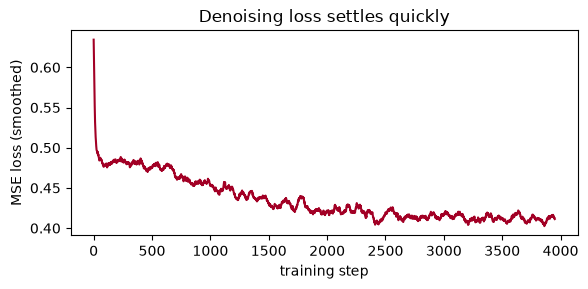

In [20]:
# betas, alphas and abar already come from the schedule cell above; nothing to redefine.

def train_ddpm(steps=4000, bs=512, lr=2e-3, seed=0):
    torch.manual_seed(seed)
    net = FieldMLP()
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    hist = []
    t0 = time.time()
    for it in range(steps):
        x0  = torch.from_numpy(sample_target(bs))
        t   = torch.randint(0, T, (bs,))
        eps = torch.randn_like(x0)
        xt  = q_sample(x0, t, eps)
        pred = net(xt, t.float() / T)
        loss = ((pred - eps) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        hist.append(loss.item())
        if (it + 1) % 1000 == 0:
            print(f"  step {it+1:>4}/{steps}   loss {np.mean(hist[-200:]):.4f}")
    print(f"Trained in {time.time()-t0:.1f}s")
    return net, hist

ddpm_net, hist = train_ddpm()

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.convolve(hist, np.ones(50)/50, mode="valid"), color="#A20025")
ax.set_xlabel("training step"); ax.set_ylabel("MSE loss (smoothed)")
ax.set_title("Denoising loss settles quickly"); fig.tight_layout(); plt.show()

## <b> <font color='#A20025'> Sampling: run the reverse process</font> </b>

Now the payoff. To **generate**, you start from pure Gaussian noise $x_T$ and repeatedly apply the learned denoiser, stepping $t = T{-}1, T{-}2, \dots, 0$. Each step nudges the point toward the data and re-injects a little fresh noise (this is the *ancestral* sampler; the original, fully stochastic DDPM reverse process).

Two things to look at below:
- **Left:** 2000 freshly generated points (red) laid over the true target (grey). A good model fills both moons with no leakage between them.
- **Right:** the **denoising trajectory** of a handful of individual points; watch them start as scattered static and get "reeled in" onto the moons.

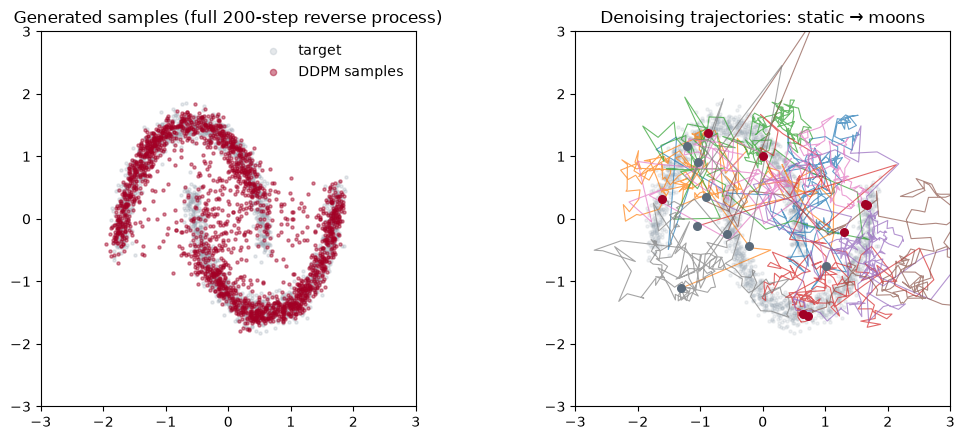

In [23]:
@torch.no_grad()
def ddpm_sample(net, n, steps=T, seed=0, record=False):
    """Ancestral reverse process, respaced to `steps` reverse iterations."""
    g = torch.Generator().manual_seed(seed)
    idx       = torch.linspace(0, T - 1, steps).round().long()   # subsequence of timesteps
    ab_sub    = abar[idx]
    ab_prev   = torch.cat([torch.ones(1, dtype=abar.dtype), ab_sub[:-1]])
    a_sub     = ab_sub / ab_prev
    b_sub     = 1 - a_sub
    x = torch.randn(n, 2, generator=g, dtype=abar.dtype)
    traj = [x.clone()]
    for i in reversed(range(steps)):
        tb  = torch.full((n,), idx[i]).to(abar.dtype) / T
        eps = net(x, tb)
        ab, a, b = ab_sub[i], a_sub[i], b_sub[i]
        mean = (x - b / (1 - ab).sqrt() * eps) / a.sqrt()
        if i > 0:
            var = b * (1 - ab_prev[i]) / (1 - ab)
            x = mean + var.sqrt() * torch.randn(n, 2, generator=g, dtype=abar.dtype)
        else:
            x = mean
        if record: traj.append(x.clone())
    return (x, traj) if record else x

gen = ddpm_sample(ddpm_net, 2000, steps=T, seed=1).numpy()
tgt = sample_target(2000, seed=99)
_, traj = ddpm_sample(ddpm_net, 8, steps=T, seed=2, record=True)
traj = torch.stack(traj).numpy()          # (T+1, 8, 2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(tgt[:, 0], tgt[:, 1], s=5, alpha=0.25, color="#9aa7b3", label="target")
axes[0].scatter(gen[:, 0], gen[:, 1], s=5, alpha=0.45, color="#A20025", label="DDPM samples")
axes[0].set_title(f"Generated samples (full {T}-step reverse process)")
axes[0].legend(frameon=False, markerscale=2); axes[0].set_aspect("equal")
axes[0].set_xlim(-3, 3); axes[0].set_ylim(-3, 3)
axes[1].scatter(tgt[:, 0], tgt[:, 1], s=5, alpha=0.15, color="#9aa7b3")
for k in range(traj.shape[1]):
    axes[1].plot(traj[:, k, 0], traj[:, k, 1], lw=0.8, alpha=0.7)
    axes[1].scatter(traj[0, k, 0], traj[0, k, 1], s=30, color="#5B6B7B", zorder=3)   # start (noise)
    axes[1].scatter(traj[-1, k, 0], traj[-1, k, 1], s=30, color="#A20025", zorder=3) # end (data)
axes[1].set_title("Denoising trajectories: static → moons"); axes[1].set_aspect("equal")
axes[1].set_xlim(-3, 3); axes[1].set_ylim(-3, 3)
fig.tight_layout(); plt.show()

![Figure I.3]({{artifact:9bfdff37-5ff5-4dfc-8b04-8f5726d2880f}})

**Figure I.3.** Running the full 200-step reverse process turns noise back into structure. Each faint trajectory is one point being carried from the Gaussian cloud on the left back onto the data manifold on the right, and the emergent two-moons shape shows the learned denoiser has captured the target distribution rather than memorizing individual points. The reverse walk is what the tiny MLP learned to perform, one small denoising step at a time.

### <b> <font color='#A20025'> A second sampler for the same network: DDIM</font> </b>

Before you cut the step budget, it is worth knowing that the sampler is a **separate choice
from the model**. The network you just trained only ever learned one thing: given a noisy point
and its noise level, name the noise. Nothing in that training pins down how you walk back down
the ladder. The ancestral sampler above is one walk; **DDIM** (Denoising Diffusion Implicit
Models, Song et al. 2021) is another, and it uses the *same weights*, the *same* cosine
schedule, and the *same* respaced subsequence of timesteps. Nothing is retrained.

The difference is what each step does with the network's answer. The ancestral update nudges
$x_t$ toward the data and then **re-injects a little fresh Gaussian noise**, because it is
sampling from a posterior that genuinely has width. DDIM turns the network's noise estimate
into an explicit guess at the clean point,

$$\hat{x}_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\,\varepsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}$$

then re-noises that guess to the *next* level down. With no fresh randomness at all, sampling
becomes a **deterministic** map from the starting noise to the final sample; the discrete
analogue of integrating an ordinary differential equation, and the same framing flow matching
uses in Notebook 2. That determinism is why DDIM is the usual way to skip noise levels.

One knob, `eta`, interpolates between the two. It scales how much fresh noise each step injects:
`eta=0` is the fully deterministic path, and `eta=1` restores exactly the ancestral posterior
width. That second claim is not a figure of speech, and the cell below checks it rather than
asserting it. Notebook 2 leans on this knob hard, because it is what lets you ask *which part*
of flow matching's step-count advantage comes from the path and which part from the randomness.

max |ancestral - DDIM(eta=1)| over 2000 samples x 3 seeds, 8 steps: 2.4e-13
(float64 machine precision, so at eta=1 the two update rules are the same map)


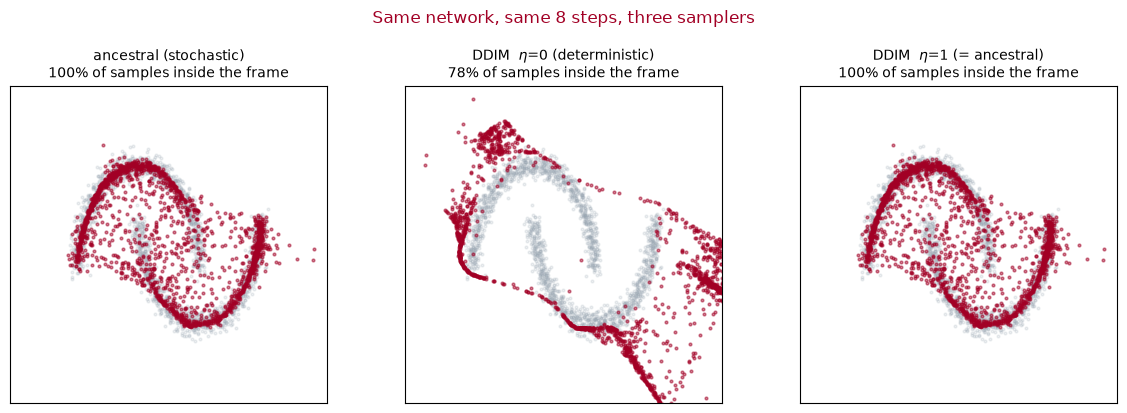

In [27]:
@torch.no_grad()
def ddim_sample(net, n, steps, eta=0.0, seed=0, record=False, x0_clip=None):
    """DDIM sampler (Song et al., 2021) on the SAME respaced ladder as ddpm_sample.

    eta=0 gives the deterministic probability-flow path; eta=1 makes the injected
    noise match the ancestral posterior std, recovering ddpm_sample exactly.
    x0_clip optionally clamps the predicted clean point, a standard stabiliser.
    """
    g = torch.Generator().manual_seed(seed)
    idx     = torch.linspace(0, T - 1, steps).round().long()   # identical respacing to ddpm_sample
    ab_sub  = abar[idx]
    ab_prev = torch.cat([torch.ones(1, dtype=abar.dtype), ab_sub[:-1]])
    x = torch.randn(n, 2, generator=g, dtype=abar.dtype)
    traj = [x.clone()]
    for i in reversed(range(steps)):
        tb  = torch.full((n,), idx[i]).to(abar.dtype) / T
        eps = net(x, tb)
        ab, abp = ab_sub[i], ab_prev[i]
        x0 = (x - (1 - ab).sqrt() * eps) / ab.sqrt()          # the explicit clean-point guess
        if x0_clip is not None:
            x0 = x0.clamp(-x0_clip, x0_clip)
        if i > 0:
            sig2 = (eta ** 2) * (1 - ab / abp) * (1 - abp) / (1 - ab)   # injected variance
            c    = (1 - abp - sig2).clamp_min(0.0).sqrt()               # deterministic share
            x    = abp.sqrt() * x0 + c * eps + sig2.sqrt() * torch.randn(n, 2, generator=g, dtype=abar.dtype)
        else:
            x = abp.sqrt() * x0 + (1 - abp).clamp_min(0.0).sqrt() * eps
        if record: traj.append(x.clone())
    return (x, traj) if record else x


# --- Check the eta=1 claim instead of trusting it. -------------------------------
# Both samplers draw from the generator at the same points, so for a shared seed they
# consume identical random streams; any difference has to come from the update rule.
# We compare in float64 so the answer is about the maths, not about float32 rounding.
_net64 = FieldMLP().double()
_net64.load_state_dict({k: v.double() for k, v in ddpm_net.state_dict().items()})
_net64.eval()
_abar32, abar = abar, abar.double()          # temporarily run the ladder in float64
_dev = max(float((ddpm_sample(_net64, 2000, steps=K, seed=s)
                  - ddim_sample(_net64, 2000, steps=K, seed=s, eta=1.0)).abs().max())
           for K in [8] for s in range(3))
abar = _abar32                                # restore
print(f"max |ancestral - DDIM(eta=1)| over 2000 samples x 3 seeds, 8 steps: {_dev:.1e}")
print("(float64 machine precision, so at eta=1 the two update rules are the same map)")

# The two samplers, same network, same 8-step budget.
tgt = sample_target(2000, seed=99)
panels = [("ancestral (stochastic)", ddpm_sample(ddpm_net, 2000, steps=8, seed=1).numpy()),
          ("DDIM  $\\eta$=0 (deterministic)", ddim_sample(ddpm_net, 2000, steps=8, seed=1, eta=0.0).numpy()),
          ("DDIM  $\\eta$=1 (= ancestral)", ddim_sample(ddpm_net, 2000, steps=8, seed=1, eta=1.0).numpy())]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, s) in zip(axes, panels):
    ax.scatter(tgt[:, 0], tgt[:, 1], s=4, alpha=0.18, color="#9aa7b3")
    ax.scatter(s[:, 0], s[:, 1], s=4, alpha=0.5, color="#A20025")
    frac = float(np.mean(np.abs(s).max(1) <= 3.0))
    ax.set_title(f"{title}\n{frac:.0%} of samples inside the frame", fontsize=10)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
fig.suptitle("Same network, same 8 steps, three samplers", y=1.02, color="#A20025")
fig.tight_layout(); plt.show()

Two things in that output are worth sitting with.

First, the identity check comes back at float64 machine precision. At `eta=1` DDIM **is** the
ancestral sampler, not an approximation of it, which means the respacing and the schedule are
shared and `eta` really is the only variable moving. That matters for Notebook 2: it turns a
qualitative argument about sampler families into a controlled experiment with one dial.

Second, and less comfortably: the **deterministic** sampler is visibly the worst of the three at
this budget. Its points spray well outside the frame while the two stochastic panels sit on the
moons. That is the opposite of what "remove the randomness and integrate a clean ODE" sounds
like it should do, and it is not a bug in the code above; the `eta=1` column proves the update
rule is right. Notebook 2 measures the effect properly, over five seeds and ten step budgets,
and then explains it. For now, register the surprise: on this ladder, the injected noise is
doing real work.

## <b> <font color='#A20025'> The catch: fewer steps, worse samples</font> </b>

That full run used **200 reverse steps**; 200 forward passes through the network to make one batch of samples. On a 2-D toy that is nothing, but for a real molecular model each step is expensive, and 200 of them per sample is a genuine bottleneck.

The obvious question: *can you just use fewer steps?* Let's try. Below you sample with progressively fewer reverse iterations and eyeball the result. Watch what happens as you squeeze the budget; the ancestral sampler holds up for a while, then **falls apart** once there are too few steps to reverse the noise safely.

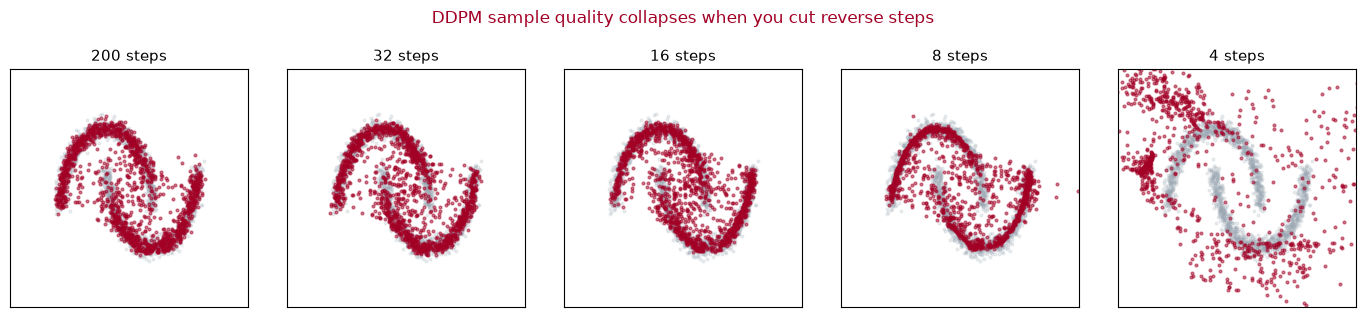

In [31]:
budgets = [200, 32, 16, 8, 4]
fig, axes = plt.subplots(1, len(budgets), figsize=(14, 3))
for ax, K in zip(axes, budgets):
    s = ddpm_sample(ddpm_net, 1500, steps=K, seed=1).numpy()
    ax.scatter(tgt[:, 0], tgt[:, 1], s=4, alpha=0.18, color="#9aa7b3")
    ax.scatter(s[:, 0], s[:, 1], s=4, alpha=0.5, color="#A20025")
    ax.set_title(f"{K} steps", fontsize=11); ax.set_aspect("equal")
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("DDPM sample quality collapses when you cut reverse steps", y=1.04, color="#A20025")
fig.tight_layout(); plt.show()

You can see the moons blur and then disintegrate as the budget shrinks; by 4 steps the ancestral
sampler is unstable. **This is the pain point that sets up the rest of the chapter.**

The reverse process is a *stochastic* walk with many small, carefully-sized steps. Take too few
and each step has to be too large; the Gaussian assumptions behind the sampler break, and points
scatter off the data.

The tempting conclusion is that the *stochasticity* is the problem, and that switching to the
deterministic DDIM path you built above would fix it. Hold that thought, because Notebook 2
measures it and the answer is the reverse. At a matched 8-step budget on this toy, the ancestral
sampler scores an energy distance of **0.041** to the target while deterministic DDIM sits at
**0.849**, twenty times worse. Both are beaten by the flow matcher's **0.010**. Cutting the
budget hurts every sampler here, but removing the noise hurts more than the budget does.

In **Notebook 2** you will meet **flow matching**, which reframes generation as following a smooth
*velocity field* along an ODE; and reaches the same sample quality in **dramatically fewer steps**.
The head-to-head number is the thesis figure of this chapter, and because you now have two
diffusion samplers rather than one, that figure can separate what the *method* buys from what the
*sampler* buys.

## <b> <font color='#A20025'> Summary</font> </b>

You built a diffusion model end to end on a 2-D toy:

- The **forward process** noises data to static with a one-shot formula $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\varepsilon$; nothing to learn.
- The **schedule** is built from per-step $\beta_t$ values clamped to a safe range, which keeps every reverse step well posed; reading $\bar\alpha_t$ off the cosine curve instead gives $\bar\alpha_0=1$ and turns the last denoising step into `NaN`.
- The **reverse process** is learned by a tiny MLP trained to **predict the noise**, with a plain MSE loss.
- **Sampling** runs that denoiser from pure noise back to data; a full 200-step run reproduces both moons cleanly.
- The **sampler is a separate choice from the model**. The same 74,882 weights support the stochastic ancestral walk and the deterministic **DDIM** path, with `eta` interpolating between them; at `eta=1` the two are the same map to machine precision.
- **But** sample quality **degrades as you cut reverse steps**; the motivating problem for flow matching. Making the sampler deterministic does not rescue it, which is the surprise Notebook 2 quantifies.

**Next (Notebook 2):** conditional flow matching on the *same* two-moons target, and the
step-count showdown; now run as a controlled three-way comparison rather than a two-way one.

### <b> <font color='#A20025'> References</font> </b>

1. Ho, Jain & Abbeel (2020), *Denoising Diffusion Probabilistic Models*, NeurIPS. arXiv:2006.11239.
2. Nichol & Dhariwal (2021), *Improved Denoising Diffusion Probabilistic Models*, ICML. arXiv:2102.09672. *(cosine schedule)*
3. Song, Meng & Ermon (2021), *Denoising Diffusion Implicit Models*, ICLR. arXiv:2010.02502. *(DDIM; the deterministic sampler and the `eta` family)*